# Prévision du risque de sécheresse


## Imports et chargement des données

In [1]:
import csv
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('XGBoost non disponible – Random Forest sera utilisé.')

# ── Chargement ──────────────────────────────────────────────
DATA_PATH = 'ex16_secheresse_spi.csv'
df = pd.read_csv(DATA_PATH)
print(f'Dimensions : {df.shape}')
print('Colonnes :', list(df.columns))
df.head(3)

Dimensions : (2520, 32)
Colonnes : ['record_id', 'governorate', 'city', 'region', 'year', 'month', 'date', 'latitude', 'longitude', 'utm32_easting', 'utm32_northing', 'population_density', 'urban_index', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'ndvi_score', 'drought_pressure_score', 'electricity_pressure_score', 'tourism_pressure_score', 'observed_index', 'data_nature', 'observed_lag_1', 'observed_lag_2', 'observed_lag_3', 'observed_lag_6', 'observed_lag_12', 'rolling_mean_3', 'rolling_mean_6', 'target_stage1_tabular_score', 'target_stage2_lstm_score', 'lstm_drought_next_3m']


,record_id,governorate,city,region,year,month,date,latitude,longitude,utm32_easting,...,observed_lag_1,observed_lag_2,observed_lag_3,observed_lag_6,observed_lag_12,rolling_mean_3,rolling_mean_6,target_stage1_tabular_score,target_stage2_lstm_score,lstm_drought_next_3m
0,EX16_Ariana_2017_01,Ariana,Ariana,Nord-Est,2017,1,2017-01-15,36.904083,10.174935,604674.28,...,20.08,31.31,58.22,75.18,20.58,36.536667,55.576667,7.22,34.82,34.82
1,EX16_Ariana_2017_02,Ariana,Ariana,Nord-Est,2017,2,2017-02-15,36.809448,10.179861,605242.86,...,14.80,20.08,31.31,83.70,18.81,22.063333,45.513333,31.86,44.84,44.84
2,EX16_Ariana_2017_03,Ariana,Ariana,Nord-Est,2017,3,2017-03-15,36.896211,10.233422,609896.45,...,24.48,14.80,20.08,64.97,40.40,19.786667,35.643333,56.46,56.82,56.82


## Préparation des données

In [2]:
#Détection des colonnes de façon défensive
cols = list(df.columns)

TARGET_TAB  = 'target_stage1_tabular_score'
TARGET_LSTM = 'lstm_drought_next_3m'

# Colonnes géographiques
GEO_COLS = [c for c in ['latitude','longitude','utm32_easting','utm32_northing'] if c in cols]

# Colonnes à exclure des features
EXCLUDE = {'record_id','date','text_fr','stage2_label_hint','data_nature',
           TARGET_TAB, TARGET_LSTM,
           'target_stage2_bert_score','text_hotel_score'} | set(GEO_COLS)

# Variables tabulaires numériques
TABULAR_FEATURES = [c for c in cols
                    if c not in EXCLUDE
                    and df[c].dtype in [np.float64, np.int64, float, int]
                    and 'lag' not in c.lower()
                    and 'lstm' not in c.lower()]
print(f'Features tabulaires ({len(TABULAR_FEATURES)}) :', TABULAR_FEATURES)

# Variables de lag (pour LSTM)
LAG_COLS = [c for c in cols if 'lag' in c.lower() or 'observed' in c.lower()
            or 'spi' in c.lower() or 'index' in c.lower()]
LAG_COLS = [c for c in LAG_COLS if c not in EXCLUDE]
print(f'Colonnes temporelles/lag ({len(LAG_COLS)}) :', LAG_COLS)

# Nettoyage
df_clean = df.dropna(subset=[TARGET_TAB]).copy()
print(f'Lignes après nettoyage cible Tab : {len(df_clean)}')

Features tabulaires (14) : ['year', 'month', 'population_density', 'urban_index', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'ndvi_score', 'drought_pressure_score', 'electricity_pressure_score', 'tourism_pressure_score', 'observed_index', 'rolling_mean_3', 'rolling_mean_6']
Colonnes temporelles/lag (7) : ['urban_index', 'observed_index', 'observed_lag_1', 'observed_lag_2', 'observed_lag_3', 'observed_lag_6', 'observed_lag_12']
Lignes après nettoyage cible Tab : 2520


In [3]:
#Données tabulaires
X_tab = df_clean[TABULAR_FEATURES].fillna(df_clean[TABULAR_FEATURES].median()).values
y_tab = df_clean[TARGET_TAB].values

X_train, X_test, y_train, y_test = train_test_split(
    X_tab, y_tab, test_size=0.2, random_state=42)
print(f'Train : {X_train.shape}   Test : {X_test.shape}')

# Fonction métriques
def metrics_report(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f'[{label}]  MAE={mae:.3f}  RMSE={rmse:.3f}  R²={r2:.4f}')
    return {'Modèle': label, 'MAE': round(mae,3), 'RMSE': round(rmse,3), 'R²': round(r2,4)}

results = []

Train : (2016, 14)   Test : (504, 14)


---
## Partie A – Modèle basique (Random Forest + XGBoost)

In [4]:
# Random Forest
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(metrics_report(y_test, pred_rf, 'RF Basique'))

# XGBoost
if HAS_XGB:
    xgb_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1,
                                  max_depth=5, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    pred_xgb = xgb_model.predict(X_test)
    results.append(metrics_report(y_test, pred_xgb, 'XGBoost Basique'))

pd.DataFrame(results)

[RF Basique]  MAE=8.791  RMSE=10.998  R²=0.8177
[XGBoost Basique]  MAE=9.168  RMSE=11.418  R²=0.8035


,Modèle,MAE,RMSE,R²
0,RF Basique,8.791,10.998,0.8177
1,XGBoost Basique,9.168,11.418,0.8035


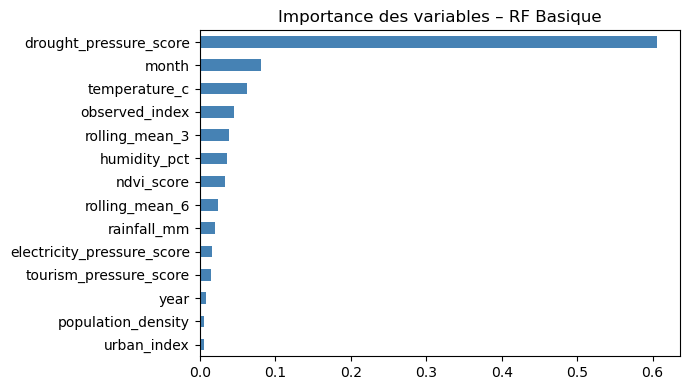

In [5]:
# Importance des features (RF)
fi = pd.Series(rf.feature_importances_, index=TABULAR_FEATURES).sort_values()
fi.plot(kind='barh', figsize=(7,4),
        title="Importance des variables – RF Basique",
        color='steelblue')
plt.tight_layout(); plt.show()

---
## Partie B – Amélioration par KMeans

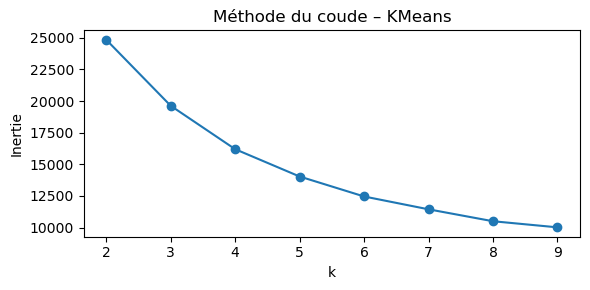

cluster
3    754
0    703
1    546
2    517
Name: count, dtype: int64


In [6]:
# Standardisation + KMeans
scaler = StandardScaler()
X_all_sc = scaler.fit_transform(
    df_clean[TABULAR_FEATURES].fillna(df_clean[TABULAR_FEATURES].median()))

# Choisir k via inertie (méthode du coude)
inertias = []
K_range = range(2, 10)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_all_sc)
    inertias.append(km.inertia_)

plt.figure(figsize=(6,3))
plt.plot(K_range, inertias, marker='o')
plt.xlabel('k'); plt.ylabel('Inertie')
plt.title('Méthode du coude – KMeans')
plt.tight_layout(); plt.show()

# Choix de k=4
K_OPTIMAL = 4
km_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df_clean = df_clean.copy()
df_clean['cluster'] = km_final.fit_predict(X_all_sc)
print(df_clean['cluster'].value_counts())

In [7]:
# Re-entraînement avec la variable cluster
FEATURES_KM = TABULAR_FEATURES + ['cluster']
X_km = df_clean[FEATURES_KM].fillna(0).values
y_km = df_clean[TARGET_TAB].values

X_train_km, X_test_km, y_train_km, y_test_km = train_test_split(
    X_km, y_km, test_size=0.2, random_state=42)

rf_km = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_km.fit(X_train_km, y_train_km)
pred_rf_km = rf_km.predict(X_test_km)
results.append(metrics_report(y_test_km, pred_rf_km, 'RF + KMeans'))

if HAS_XGB:
    xgb_km = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1,
                               max_depth=5, random_state=42, verbosity=0)
    xgb_km.fit(X_train_km, y_train_km)
    pred_xgb_km = xgb_km.predict(X_test_km)
    results.append(metrics_report(y_test_km, pred_xgb_km, 'XGBoost + KMeans'))

pd.DataFrame(results)

[RF + KMeans]  MAE=8.790  RMSE=10.980  R²=0.8183
[XGBoost + KMeans]  MAE=9.098  RMSE=11.353  R²=0.8057


,Modèle,MAE,RMSE,R²
0,RF Basique,8.791,10.998,0.8177
1,XGBoost Basique,9.168,11.418,0.8035
2,RF + KMeans,8.790,10.980,0.8183
3,XGBoost + KMeans,9.098,11.353,0.8057


---
## Partie C – Réseau de neurones MLP avec tuning

[MLP non tuné]  MAE=9.064  RMSE=11.407  R²=0.8039


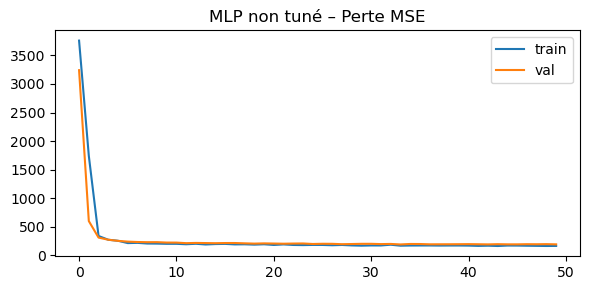

In [8]:
tf.random.set_seed(42)

# Standardisation pour MLP
sc_mlp = StandardScaler()
X_train_sc = sc_mlp.fit_transform(X_train)
X_test_sc  = sc_mlp.transform(X_test)

def build_mlp(n_layers=2, n_units=64, dropout=0.2, lr=1e-3, input_dim=10):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for _ in range(n_layers):
        model.add(layers.Dense(n_units, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse')
    return model

# MLP non tuné
mlp_base = build_mlp(input_dim=X_train_sc.shape[1])
hist = mlp_base.fit(X_train_sc, y_train, epochs=50, batch_size=32,
                    validation_split=0.1, verbose=0)
pred_mlp_base = mlp_base.predict(X_test_sc, verbose=0).flatten()
results.append(metrics_report(y_test, pred_mlp_base, 'MLP non tuné'))

# Courbe de perte
plt.figure(figsize=(6,3))
plt.plot(hist.history['loss'], label='train')
plt.plot(hist.history['val_loss'], label='val')
plt.title('MLP non tuné – Perte MSE'); plt.legend()
plt.tight_layout(); plt.show()

In [9]:
# Grille de tuning
grid = [
    {'n_layers':2, 'n_units':64,  'dropout':0.2, 'lr':1e-3, 'batch':32, 'epochs':80},
    {'n_layers':3, 'n_units':128, 'dropout':0.3, 'lr':5e-4, 'batch':64, 'epochs':100},
    {'n_layers':2, 'n_units':128, 'dropout':0.1, 'lr':1e-3, 'batch':16, 'epochs':80},
    {'n_layers':3, 'n_units':64,  'dropout':0.3, 'lr':1e-3, 'batch':32, 'epochs':100},
]

best_r2_mlp, best_preds_mlp = -np.inf, None
for cfg in grid:
    tf.random.set_seed(42)
    m = build_mlp(n_layers=cfg['n_layers'], n_units=cfg['n_units'],
                  dropout=cfg['dropout'], lr=cfg['lr'],
                  input_dim=X_train_sc.shape[1])
    m.fit(X_train_sc, y_train, epochs=cfg['epochs'],
          batch_size=cfg['batch'], validation_split=0.1, verbose=0)
    p = m.predict(X_test_sc, verbose=0).flatten()
    r2 = r2_score(y_test, p)
    print(f"layers={cfg['n_layers']} units={cfg['n_units']} drop={cfg['dropout']} "
          f"lr={cfg['lr']} batch={cfg['batch']} epochs={cfg['epochs']} -> R²={r2:.4f}")
    if r2 > best_r2_mlp:
        best_r2_mlp = r2; best_preds_mlp = p

print(f'\nMeilleur R² MLP tuné : {best_r2_mlp:.4f}')
results.append(metrics_report(y_test, best_preds_mlp, 'MLP Tuné'))
pd.DataFrame(results)

layers=2 units=64 drop=0.2 lr=0.001 batch=32 epochs=80 -> R²=0.8139
layers=3 units=128 drop=0.3 lr=0.0005 batch=64 epochs=100 -> R²=0.8016
layers=2 units=128 drop=0.1 lr=0.001 batch=16 epochs=80 -> R²=0.8132
layers=3 units=64 drop=0.3 lr=0.001 batch=32 epochs=100 -> R²=0.8133

Meilleur R² MLP tuné : 0.8139
[MLP Tuné]  MAE=8.793  RMSE=11.113  R²=0.8139


,Modèle,MAE,RMSE,R²
0,RF Basique,8.791,10.998,0.8177
1,XGBoost Basique,9.168,11.418,0.8035
2,RF + KMeans,8.790,10.980,0.8183
3,XGBoost + KMeans,9.098,11.353,0.8057
4,MLP non tuné,9.064,11.407,0.8039
5,MLP Tuné,8.793,11.113,0.8139


---
## Partie D – Modélisation temporelle LSTM

In [10]:
# Colonnes candidates pour séquence temporelle
SEQ_CANDIDATES = [c for c in df_clean.columns
                  if any(k in c.lower() for k in
                         ['observed','spi','index','lag','month','humidity',
                          'rainfall','temperature'])]
SEQ_CANDIDATES = [c for c in SEQ_CANDIDATES
                  if df_clean[c].dtype in [np.float64, np.int64]]
print('Colonnes séquentielles détectées :', SEQ_CANDIDATES)

# Cible
if TARGET_LSTM in df_clean.columns:
    y_lstm_raw = df_clean[TARGET_LSTM].fillna(method='ffill').values
else:
    # Construction synthétique : décalage de 3 mois de la cible principale
    print(f"Colonne '{TARGET_LSTM}' absente → construction par décalage de 3")
    y_lstm_raw = df_clean[TARGET_TAB].shift(-3).fillna(method='ffill').values

# Variables de séquence
if SEQ_CANDIDATES:
    SEQ_FEATURES = SEQ_CANDIDATES[:6]   # max 6 pour limiter la taille
else:
    SEQ_FEATURES = TABULAR_FEATURES[:6]

print('Features LSTM :', SEQ_FEATURES)

Colonnes séquentielles détectées : ['month', 'urban_index', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'observed_index', 'observed_lag_1', 'observed_lag_2', 'observed_lag_3', 'observed_lag_6', 'observed_lag_12']
Features LSTM : ['month', 'urban_index', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'observed_index']


In [11]:
#Construction des fenêtres temporelles
def build_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(len(X) - window):
        Xs.append(X[i:i+window])
        ys.append(y[i+window])
    return np.array(Xs), np.array(ys)

X_seq_raw = df_clean[SEQ_FEATURES].fillna(0).values
sc_seq = StandardScaler()
X_seq_sc = sc_seq.fit_transform(X_seq_raw)

WINDOW = 12   # fenêtre non tunée
Xs, ys = build_sequences(X_seq_sc, y_lstm_raw, window=WINDOW)
print(f'Séquences : {Xs.shape}   Cibles : {ys.shape}')

split = int(len(Xs)*0.8)
Xs_tr, Xs_te = Xs[:split], Xs[split:]
ys_tr, ys_te = ys[:split], ys[split:]

Séquences : (2508, 12, 6)   Cibles : (2508,)


In [12]:
#LSTM non tuné
def build_lstm(n_layers=1, n_units=32, dropout=0.2, lr=1e-3,
               window=12, n_features=6):
    model = keras.Sequential()
    model.add(layers.Input(shape=(window, n_features)))
    for i in range(n_layers):
        return_seq = (i < n_layers - 1)
        model.add(layers.LSTM(n_units, return_sequences=return_seq,
                              dropout=dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse')
    return model

tf.random.set_seed(42)
lstm_base = build_lstm(n_layers=1, n_units=32, dropout=0.2, lr=1e-3,
                       window=WINDOW, n_features=len(SEQ_FEATURES))
lstm_base.fit(Xs_tr, ys_tr, epochs=30, batch_size=32,
              validation_split=0.1, verbose=0)
pred_lstm_base = lstm_base.predict(Xs_te, verbose=0).flatten()
results.append(metrics_report(ys_te, pred_lstm_base, 'LSTM non tuné'))
print()

[LSTM non tuné]  MAE=20.769  RMSE=24.515  R²=-0.1398



In [13]:
#LSTM tuné – grille
lstm_grid = [
    {'win':12, 'layers':1, 'units':32,  'drop':0.2, 'lr':1e-3, 'batch':32, 'epochs':50},
    {'win':12, 'layers':2, 'units':64,  'drop':0.2, 'lr':5e-4, 'batch':16, 'epochs':80},
    {'win':24, 'layers':1, 'units':64,  'drop':0.3, 'lr':1e-3, 'batch':32, 'epochs':60},
    {'win':24, 'layers':2, 'units':128, 'drop':0.3, 'lr':1e-4, 'batch':64, 'epochs':100},
    {'win':6,  'layers':2, 'units':32,  'drop':0.1, 'lr':1e-3, 'batch':16, 'epochs':60},
]

best_r2_lstm, best_preds_lstm = -np.inf, None
for cfg in lstm_grid:
    tf.random.set_seed(42)
    Xw, yw = build_sequences(X_seq_sc, y_lstm_raw, window=cfg['win'])
    s = int(len(Xw)*0.8)
    m = build_lstm(n_layers=cfg['layers'], n_units=cfg['units'],
                   dropout=cfg['drop'], lr=cfg['lr'],
                   window=cfg['win'], n_features=len(SEQ_FEATURES))
    m.fit(Xw[:s], yw[:s], epochs=cfg['epochs'],
          batch_size=cfg['batch'], validation_split=0.1, verbose=0)
    p = m.predict(Xw[s:], verbose=0).flatten()
    r2 = r2_score(yw[s:], p)
    print(f"win={cfg['win']} layers={cfg['layers']} units={cfg['units']} "
          f"drop={cfg['drop']} lr={cfg['lr']} batch={cfg['batch']} "
          f"epochs={cfg['epochs']} -> R²={r2:.4f}")
    if r2 > best_r2_lstm:
        best_r2_lstm = r2; best_preds_lstm = p; best_ys_te = yw[s:]

print(f'\nMeilleur R² LSTM tuné : {best_r2_lstm:.4f}')
results.append(metrics_report(best_ys_te, best_preds_lstm, 'LSTM Tuné'))
pd.DataFrame(results)

win=12 layers=1 units=32 drop=0.2 lr=0.001 batch=32 epochs=50 -> R²=0.7537
win=12 layers=2 units=64 drop=0.2 lr=0.0005 batch=16 epochs=80 -> R²=0.9442
win=24 layers=1 units=64 drop=0.3 lr=0.001 batch=32 epochs=60 -> R²=0.9161
win=24 layers=2 units=128 drop=0.3 lr=0.0001 batch=64 epochs=100 -> R²=-0.3685
win=6 layers=2 units=32 drop=0.1 lr=0.001 batch=16 epochs=60 -> R²=0.9298

Meilleur R² LSTM tuné : 0.9442
[LSTM Tuné]  MAE=4.363  RMSE=5.423  R²=0.9442


,Modèle,MAE,RMSE,R²
0,RF Basique,8.791,10.998,0.8177
1,XGBoost Basique,9.168,11.418,0.8035
2,RF + KMeans,8.790,10.980,0.8183
3,XGBoost + KMeans,9.098,11.353,0.8057
4,MLP non tuné,9.064,11.407,0.8039
5,MLP Tuné,8.793,11.113,0.8139
6,LSTM non tuné,20.769,24.515,-0.1398
7,LSTM Tuné,4.363,5.423,0.9442


---
## Partie E – Discussion comparative

          Modèle    MAE   RMSE      R²
      RF Basique  8.791 10.998  0.8177
 XGBoost Basique  9.168 11.418  0.8035
     RF + KMeans  8.790 10.980  0.8183
XGBoost + KMeans  9.098 11.353  0.8057
    MLP non tuné  9.064 11.407  0.8039
        MLP Tuné  8.793 11.113  0.8139
   LSTM non tuné 20.769 24.515 -0.1398
       LSTM Tuné  4.363  5.423  0.9442


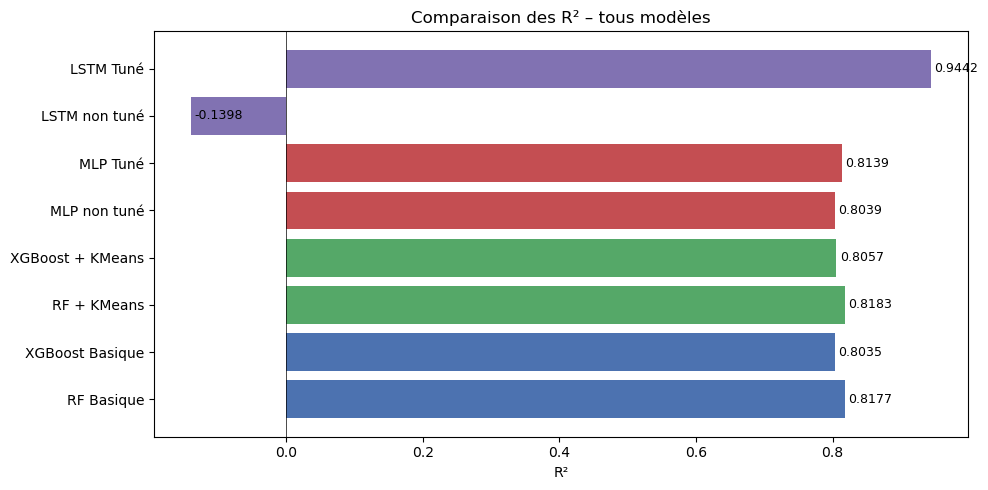

In [14]:
df_res = pd.DataFrame(results)
print(df_res.to_string(index=False))

palette = ['#4C72B0','#4C72B0','#55A868','#55A868',
           '#C44E52','#C44E52','#8172B2','#8172B2']
fig, ax = plt.subplots(figsize=(10,5))
bars = ax.barh(df_res['Modèle'], df_res['R²'],
               color=palette[:len(df_res)])
ax.axvline(0, color='k', linewidth=0.5)
ax.set_xlabel('R²'); ax.set_title('Comparaison des R² – tous modèles')
for bar, val in zip(bars, df_res['R²']):
    ax.text(bar.get_width()+0.005, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

### Interprétation

Les modèles tabulaires donnent de bons résultats, avec un R² autour de **0.80 à 0.82**.  
L’ajout de **KMeans** améliore très légèrement les performances, surtout pour Random Forest.

Le **MLP tuné** est meilleur que le MLP non tuné, ce qui montre l’intérêt du réglage des hyperparamètres.

Le meilleur modèle est le **LSTM tuné** avec un **R² = 0.9442**. Il est nettement supérieur car il utilise des **séquences temporelles**, adaptées à la prédiction du risque de sécheresse sur les 3 prochains mois.

Le **LSTM non tuné** donne un R² négatif, ce qui signifie qu’il fait pire qu’une prédiction moyenne. Cela montre que le LSTM est très sensible au tuning.

---
## Bonus – Cartographie en UTM 32N

Nombre de points valides : 2520
Écart moyen Easting : 0.02 m
Écart moyen Northing : 0.03 m
Points WGS84 après filtrage : 2296
Points UTM après filtrage : 2298


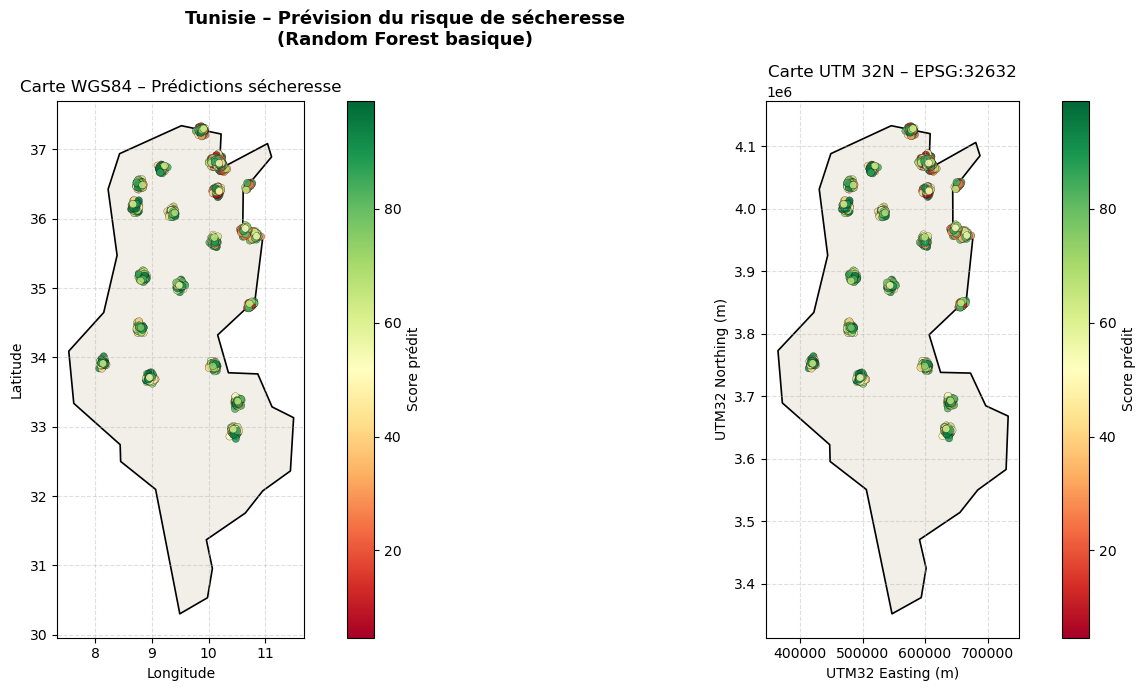

Carte sauvegardée : carte_secheresse.png


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from pyproj import Transformer

# 1. Prédictions du modèle sur tout le dataset
X_full = df_clean[TABULAR_FEATURES].fillna(df_clean[TABULAR_FEATURES].median()).values
pred_full = rf.predict(X_full)

df_map = df_clean[GEO_COLS].copy()
df_map["score_predit"] = pred_full

# Vérification des colonnes minimales
needed_cols = ["latitude", "longitude", "utm32_easting", "utm32_northing", "score_predit"]
missing_cols = [c for c in needed_cols if c not in df_map.columns]

if missing_cols:
    print("Colonnes manquantes :", missing_cols)
else:
    # 2. Conversion des colonnes en numérique
    for col in needed_cols:
        df_map[col] = pd.to_numeric(df_map[col], errors="coerce")

    df_map = df_map.dropna(subset=needed_cols).copy()

    # Garder uniquement les coordonnées plausibles en Tunisie
    df_map = df_map[
        (df_map["latitude"].between(29, 38)) &
        (df_map["longitude"].between(7, 12))
    ].copy()

    print("Nombre de points valides :", len(df_map))

    # 3. Vérification de la projection UTM 32N
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:32632", always_xy=True)

    easting_calc, northing_calc = transformer.transform(
        df_map["longitude"].values,
        df_map["latitude"].values
    )

    df_map["utm32_easting_calc"] = easting_calc
    df_map["utm32_northing_calc"] = northing_calc

    df_map["diff_easting"] = abs(df_map["utm32_easting"] - df_map["utm32_easting_calc"])
    df_map["diff_northing"] = abs(df_map["utm32_northing"] - df_map["utm32_northing_calc"])

    print("Écart moyen Easting :", round(df_map["diff_easting"].mean(), 2), "m")
    print("Écart moyen Northing :", round(df_map["diff_northing"].mean(), 2), "m")

    # 4. Charger le contour de la Tunisie
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
    world = gpd.read_file(url)

    if "ADMIN" in world.columns:
        tunisia_wgs84 = world[world["ADMIN"] == "Tunisia"].copy()
    else:
        tunisia_wgs84 = world[world["NAME"] == "Tunisia"].copy()

    # 5. GeoDataFrames des points
    # Points en WGS84
    gdf_points_wgs84 = gpd.GeoDataFrame(
        df_map.copy(),
        geometry=gpd.points_from_xy(df_map["longitude"], df_map["latitude"]),
        crs="EPSG:4326"
    )

    # Points en UTM32N
    gdf_points_utm = gpd.GeoDataFrame(
        df_map.copy(),
        geometry=gpd.points_from_xy(df_map["utm32_easting"], df_map["utm32_northing"]),
        crs="EPSG:32632"
    )

    # Contour Tunisie en UTM
    tunisia_utm = tunisia_wgs84.to_crs("EPSG:32632")

    # 6. Filtrage spatial pour éviter les points hors contour
    # En WGS84
    tunisia_geom_wgs84 = tunisia_wgs84.unary_union
    gdf_points_wgs84 = gdf_points_wgs84[gdf_points_wgs84.within(tunisia_geom_wgs84.buffer(0.05))].copy()

    # En UTM32N avec légère tolérance de 5 km
    tunisia_geom_utm = tunisia_utm.unary_union
    gdf_points_utm = gdf_points_utm[gdf_points_utm.within(tunisia_geom_utm.buffer(5000))].copy()

    print("Points WGS84 après filtrage :", len(gdf_points_wgs84))
    print("Points UTM après filtrage :", len(gdf_points_utm))

    # 7. Affichage des cartes
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    norm = Normalize(vmin=df_map["score_predit"].min(), vmax=df_map["score_predit"].max())
    sm = ScalarMappable(cmap="RdYlGn", norm=norm)
    sm.set_array([])

    # ------------------ Carte WGS84 ------------------
    tunisia_wgs84.plot(
        ax=axes[0],
        color="#f2efe9",
        edgecolor="black",
        linewidth=1.2
    )

    gdf_points_wgs84.plot(
        ax=axes[0],
        column="score_predit",
        cmap="RdYlGn",
        markersize=28,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.2
    )

    plt.colorbar(sm, ax=axes[0]).set_label("Score prédit")
    axes[0].set_title("Carte WGS84 – Prédictions sécheresse")
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    axes[0].grid(True, linestyle="--", alpha=0.4)

    # ------------------ Carte UTM 32N ------------------
    tunisia_utm.plot(
        ax=axes[1],
        color="#f2efe9",
        edgecolor="black",
        linewidth=1.2
    )

    gdf_points_utm.plot(
        ax=axes[1],
        column="score_predit",
        cmap="RdYlGn",
        markersize=28,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.2
    )

    plt.colorbar(sm, ax=axes[1]).set_label("Score prédit")
    axes[1].set_title("Carte UTM 32N – EPSG:32632")
    axes[1].set_xlabel("UTM32 Easting (m)")
    axes[1].set_ylabel("UTM32 Northing (m)")
    axes[1].grid(True, linestyle="--", alpha=0.4)

    # Titre global
    plt.suptitle(
        "Tunisie – Prévision du risque de sécheresse\n(Random Forest basique)",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.savefig("carte_secheresse.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("Carte sauvegardée : carte_secheresse.png")

In [17]:
# Vérification projection UTM 32N
try:
    from pyproj import Transformer
    t = Transformer.from_crs('EPSG:4326','EPSG:32632', always_xy=True)
    sample = df_clean[['longitude','latitude','utm32_easting','utm32_northing']].head(5)
    for _, row in sample.iterrows():
        e, n = t.transform(row['longitude'], row['latitude'])
        print(f'Calculé E={e:.0f} N={n:.0f}  |  Fichier E={row["utm32_easting"]:.0f} N={row["utm32_northing"]:.0f}')
except Exception:
    print('pyproj non installé – les colonnes utm32_easting/northing correspondent à EPSG:32632.')
    print(df_clean[GEO_COLS].head(3))

Calculé E=604674 N=4084877  |  Fichier E=604674 N=4084877
Calculé E=605243 N=4074383  |  Fichier E=605243 N=4074383
Calculé E=609896 N=4084069  |  Fichier E=609896 N=4084069
Calculé E=603406 N=4084100  |  Fichier E=603406 N=4084100
Calculé E=600402 N=4079699  |  Fichier E=600402 N=4079699


---
## Tableau récapitulatif final

In [18]:
df_final = pd.DataFrame(results)
df_final.style \
    .background_gradient(subset=['R²'], cmap='RdYlGn') \
    .format({'MAE':'{:.3f}','RMSE':'{:.3f}','R²':'{:.4f}'})

,Modèle,MAE,RMSE,R²
0,RF Basique,8.791,10.998,0.8177
1,XGBoost Basique,9.168,11.418,0.8035
2,RF + KMeans,8.790,10.980,0.8183
3,XGBoost + KMeans,9.098,11.353,0.8057
4,MLP non tuné,9.064,11.407,0.8039
5,MLP Tuné,8.793,11.113,0.8139
6,LSTM non tuné,20.769,24.515,-0.1398
7,LSTM Tuné,4.363,5.423,0.9442
